A CVE (Common Vulnerabilities and Exposures) is a unique identifier for a publicly disclosed security vulnerability in software or hardware.

Each CVE entry provides:

CVE ID (e.g., CVE-2023-12345)
Description of the vulnerability
Severity Level (LOW, MEDIUM, HIGH, CRITICAL)
CVSS Score (Numerical severity rating from 0–10)
Affected Products (Routers, operating systems, software, etc.)
References (Links to security advisories, patches, etc.)

📌 Example of a CVE Entry

CVE-2023-28771 (Zyxel Router Vulnerability)

🔴 Severity: CRITICAL

📊 CVSS Score: 9.8

📝 Description:

"A command injection vulnerability in the web interface of multiple Zyxel firewall products allows attackers to execute arbitrary commands remotely without authentication."
🔗 Reference: Zyxel Advisory

🚀 Why Does This Matter for Our Project?

We are analyzing CVE data for routers to predict their security risk.
CVSS Scores and Severity Levels help classify vulnerabilities.
A good ML model can predict the risk of a router based on CVE data

In [1]:
import pandas as pd

# Load cleaned dataset
df = pd.read_csv("data/router_cve_data_final.csv")

# Display the first few rows
print("\n✅ Cleaned Dataset Loaded Successfully!")

# Show basic info
print("\n🔍 Dataset Overview:")
print(df.info())

# Show first few rows
print("\n📝 First 5 Rows:")
print(df.head())



✅ Cleaned Dataset Loaded Successfully!

🔍 Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1662 entries, 0 to 1661
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Vendor         1662 non-null   object 
 1   CVE_ID         1662 non-null   object 
 2   Description    1662 non-null   object 
 3   Severity       1662 non-null   object 
 4   Score          1662 non-null   float64
 5   Published      1662 non-null   object 
 6   Last Modified  1662 non-null   object 
dtypes: float64(1), object(6)
memory usage: 91.0+ KB
None

📝 First 5 Rows:
  Vendor         CVE_ID                                        Description  \
0  cisco  CVE-1999-0063  Cisco IOS 12.0 and other versions can be crash...   
1  cisco  CVE-1999-0157  Cisco PIX firewall and CBAC IP fragmentation a...   
2  cisco  CVE-1999-0158  Cisco PIX firewall manager (PFM) on Windows NT...   
3  cisco  CVE-1999-0159  Attackers can crash a Cis

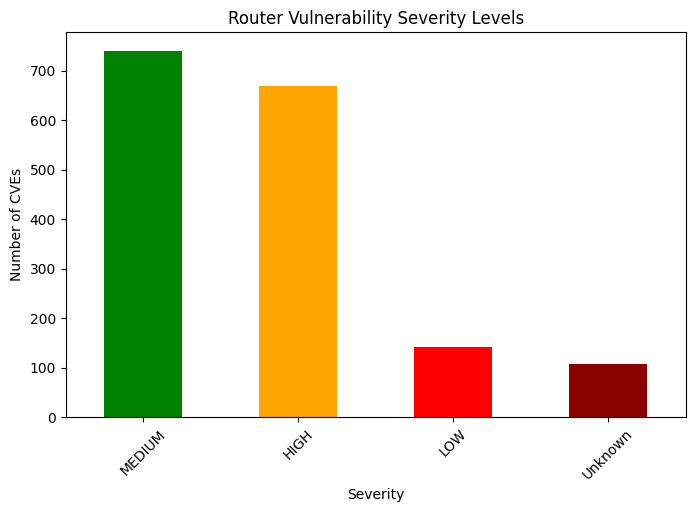

In [2]:
# Are most vulnerabilites in our dataset high-risk?? let's find out!


import matplotlib.pyplot as plt

# Count occurrences of each severity level
severity_counts = df["Severity"].value_counts()

# Plot severity distribution
plt.figure(figsize=(8, 5))
severity_counts.plot(kind="bar", color=['green', 'orange', 'red', 'darkred'])
plt.title("Router Vulnerability Severity Levels")
plt.xlabel("Severity")
plt.ylabel("Number of CVEs")
plt.xticks(rotation=45)
plt.show()



<Figure size 1200x600 with 0 Axes>

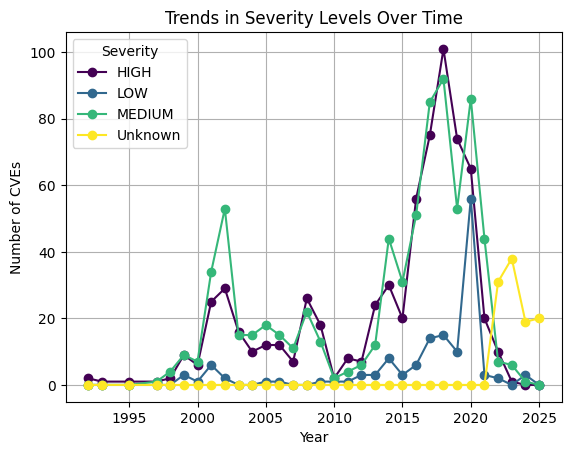

In [4]:
import seaborn as sns

# Convert Published date to datetime format (if not done already)
df["Published"] = pd.to_datetime(df["Published"])

# Create a year column
df["Year"] = df["Published"].dt.year

# Group by Year and Severity
severity_trends = df.groupby(["Year", "Severity"]).size().unstack().fillna(0)

# Plot
plt.figure(figsize=(12, 6))
severity_trends.plot(kind="line", marker="o", colormap="viridis")
plt.title("Trends in Severity Levels Over Time")
plt.xlabel("Year")
plt.ylabel("Number of CVEs")
plt.grid(True)
plt.show()


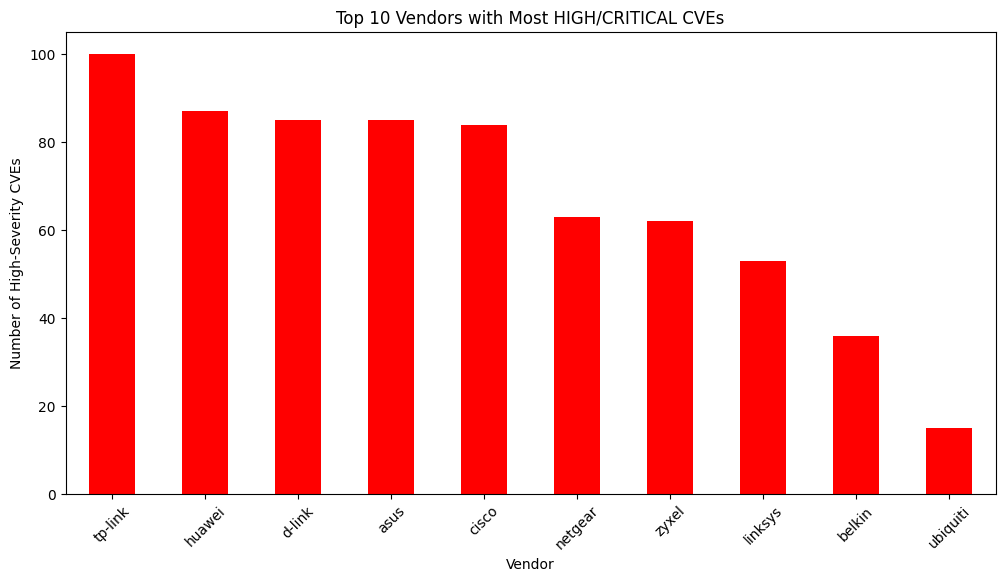

In [5]:
import seaborn as sns

plt.figure(figsize=(12, 6))
df[df["Severity"].isin(["HIGH", "CRITICAL"])].groupby("Vendor").size().nlargest(10).plot(kind="bar", color="red")
plt.title("Top 10 Vendors with Most HIGH/CRITICAL CVEs")
plt.xlabel("Vendor")
plt.ylabel("Number of High-Severity CVEs")
plt.xticks(rotation=45)
plt.show()


C:\Users\munii\AppData\Local\Temp\ipykernel_2732\2710262604.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Severity", y="Score", data=df, palette="coolwarm")


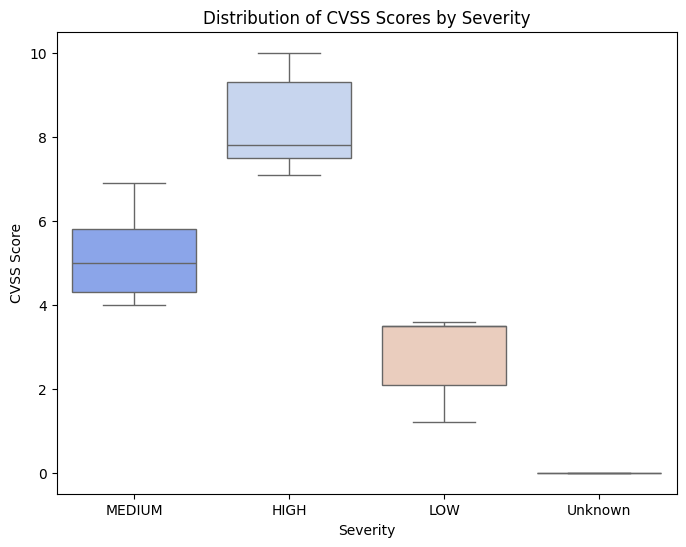

In [6]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(x="Severity", y="Score", data=df, palette="coolwarm")
plt.title("Distribution of CVSS Scores by Severity")
plt.xlabel("Severity")
plt.ylabel("CVSS Score")
plt.show()


In [11]:
# Define severity mapping
severity_mapping = {
    "LOW": 1,
    "MEDIUM": 2,
    "HIGH": 3,
    "CRITICAL": 4,
    "Unknown": 0  # Placeholder for unknown severity
}

# Apply mapping
df["Severity_Num"] = df["Severity"].map(severity_mapping)



In [13]:
from datetime import datetime

# Convert "Published" to datetime format
df["Published"] = pd.to_datetime(df["Published"])

# Calculate the age of CVE in years
current_year = datetime.now().year
df["CVE_Age"] = current_year - df["Published"].dt.year


In [15]:
from datetime import datetime

# Convert "Published" to datetime format
df["Published"] = pd.to_datetime(df["Published"])

# Calculate the age of CVE in years
current_year = datetime.now().year
df["CVE_Age"] = current_year - df["Published"].dt.year


In [16]:
# Count CVEs per vendor
vendor_cve_counts = df["Vendor"].value_counts().to_dict()

# Assign vendor risk scores
df["Vendor_Risk"] = df["Vendor"].map(vendor_cve_counts)


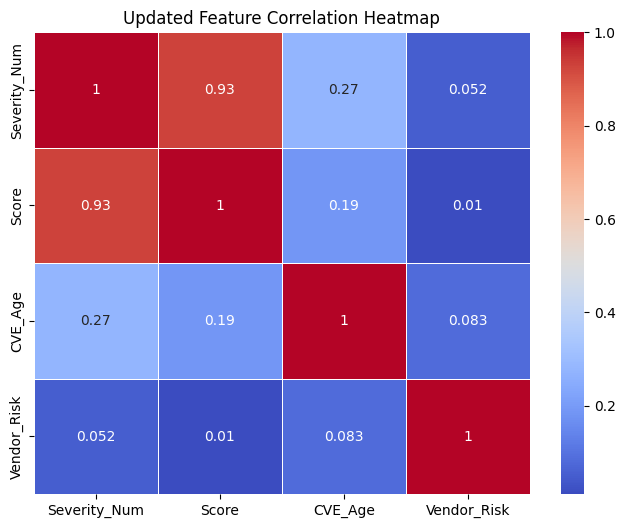

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns
numeric_df = df[["Severity_Num", "Score", "CVE_Age", "Vendor_Risk"]]

# Compute correlation matrix
correlation_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=0.5)
plt.title("Updated Feature Correlation Heatmap")
plt.show()


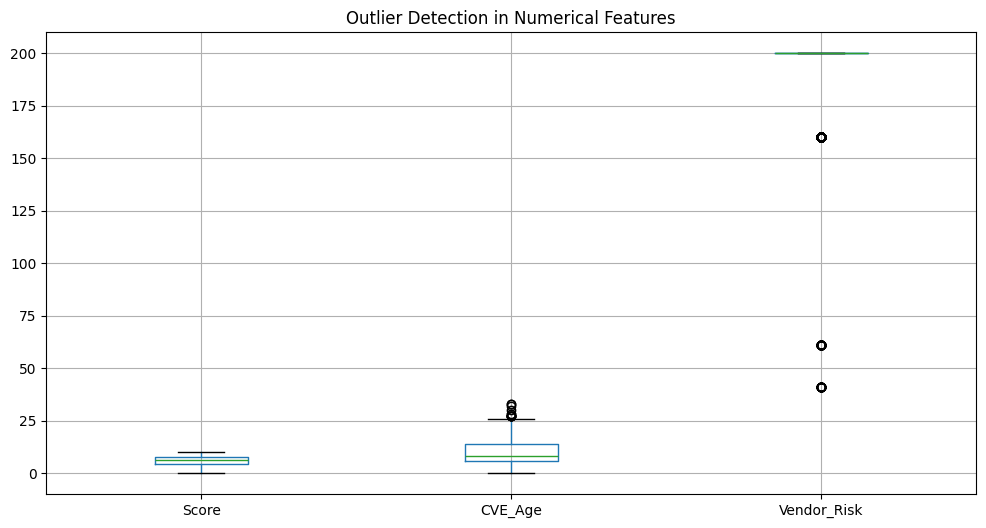

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
df[["Score", "CVE_Age", "Vendor_Risk"]].boxplot()
plt.title("Outlier Detection in Numerical Features")
plt.show()


In [20]:
# Remove vulnerabilities older than 30 years
df = df[df["CVE_Age"] <= 30]

print(f"✅ After filtering, dataset now has {df.shape[0]} rows.")


✅ After filtering, dataset now has 1659 rows.


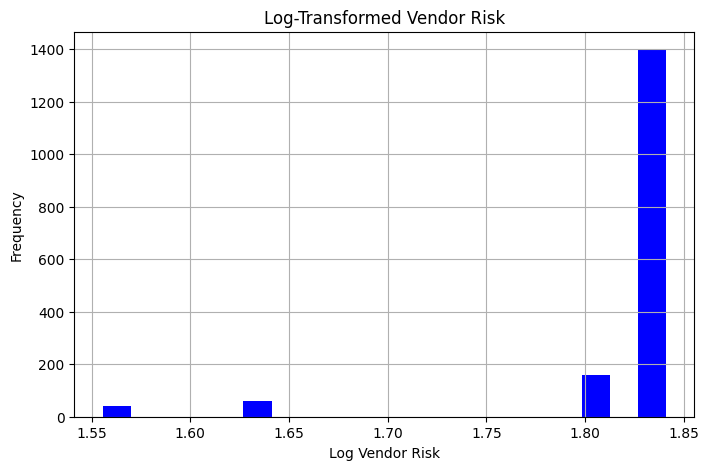

In [22]:
import numpy as np

# Apply log transformation using .loc[]
df.loc[:, "Vendor_Risk"] = np.log1p(df["Vendor_Risk"])  # log(1 + value) to handle zero values

# Check new distribution
plt.figure(figsize=(8, 5))
df["Vendor_Risk"].hist(bins=20, color="blue")
plt.title("Log-Transformed Vendor Risk")
plt.xlabel("Log Vendor Risk")
plt.ylabel("Frequency")
plt.show()
